# Tiempo hasta contención de incidentes públicos

## Resultado del corte
De 10.596 filas, 298 (2,81 %) tienen duración y unidad utilizables tras excluir identificadores duplicados. En esas 298, la mediana es 3 días y el percentil 90 es 60 días con mes de 30 días. No representa la población de incidentes.

## Pregunta para continuidad y resiliencia
¿Cómo se distribuyen los tiempos registrados hasta la **contención** de incidentes cibernéticos públicos, y qué sensibilidad tienen los percentiles a la conversión de unidades? El resultado sirve para estudiar la variable disponible, no para comprometer un objetivo de recuperación. Contención limita el incidente; no equivale a restauración de servicio ni a recuperación completa.

## Datos y supuestos
Fuente: [VERIS Community Database (VCDB)](https://github.com/vz-risk/VCDB), archivo CSV incluido en el ZIP público. Se fija el commit `5ebf2f5be85d03ff7e7455f254a3e7d1d7fd671c` y se verifica SHA-256; requiere descarga de 15 MB y lectura parcial de un CSV de unos 172 MB. La licencia del repositorio figura como `NOASSERTION` en su metadato: se descarga de la fuente y no se redistribuye aquí.

Los registros son incidentes publicados y seleccionados; la notificación y codificación pueden variar. Se restringe a duración positiva, una única unidad interpretable e identificador único. No se conoce si los valores ausentes son incidentes sin contención, censura o falta de información: no se imputa cero ni se tratan como censurados. El estimando es la proporción entre los registros con tiempo disponible, no la probabilidad futura de recuperación de una empresa.

**Entorno:** Python, curl, pandas, numpy, scipy, matplotlib y Jupyter; necesita internet y espacio temporal. El análisis no usa información confidencial.

## 1. Descarga fija y huella

In [1]:
import hashlib, tempfile, subprocess, zipfile, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
commit='5ebf2f5be85d03ff7e7455f254a3e7d1d7fd671c'
expected='59d42136cf5868c9c4fdf0991e8b4d57d29f6fcb6f2a0ce609ee777c453bdbca'
url=f'https://raw.githubusercontent.com/vz-risk/VCDB/{commit}/data/csv/vcdb.csv.zip'
archive=Path(tempfile.gettempdir())/'vcdb-5ebf2f5.zip'
if not archive.exists() or hashlib.sha256(archive.read_bytes()).hexdigest()!=expected:
    subprocess.run(['curl','-fsSL','--max-time','120',url,'-o',str(archive)],check=True)
actual=hashlib.sha256(archive.read_bytes()).hexdigest()
assert actual==expected, 'La descarga no coincide con el SHA-256 fijado'
print('SHA-256 ZIP:',actual)

SHA-256 ZIP: 59d42136cf5868c9c4fdf0991e8b4d57d29f6fcb6f2a0ce609ee777c453bdbca


## 2. Selección de columnas y control de registros

In [2]:
value='timeline.containment.value'; year='timeline.incident.year'; prefix='timeline.containment.unit.'
with zipfile.ZipFile(archive) as z:
    with z.open('vcdb.csv') as f:
        data=pd.read_csv(f,usecols=lambda x:x in ['incident_id',value,year] or x.startswith(prefix),low_memory=False)
duplicate=data.incident_id.duplicated(keep=False)
print('Filas con identificador ausente:',int(data.incident_id.isna().sum()),'| filas con ID duplicado excluidas:',int(duplicate.sum()))
unit_cols=[x for x in data.columns if x.startswith(prefix)]
unit_flags=data[unit_cols].eq(True)
valid=data.incident_id.notna() & ~duplicate & data[value].notna() & (data[value]>0) & (unit_flags.sum(axis=1)==1)
valid &= ~unit_flags[[x for x in unit_cols if x.split('.')[-1] in ['Unknown','Never','NA']]].any(axis=1)
subset=data.loc[valid].copy()
subset['unit']=unit_flags.loc[valid].idxmax(axis=1).str.removeprefix(prefix)
print('Total registros:',len(data),'| Contención con valor y unidad:',len(subset),'| Fracción retenida:',round(len(subset)/len(data),4))
print('Años observados con duración:',int(subset[year].min()),'a',int(subset[year].max()))
subset.unit.value_counts().to_frame('registros')

Filas con identificador ausente: 0 | filas con ID duplicado excluidas: 241
Total registros: 10596 | Contención con valor y unidad: 298 | Fracción retenida: 0.0281
Años observados con duración: 2000 a 2026


,registros
unit,
Days,147
Hours,47
Weeks,42
Months,41
Minutes,13
Years,8


## 3. Escala común y distribución
Se convierten horas, minutos y semanas a días exactos. Meses y años son unidades aproximadas: se usan 30 y 365 días como referencia; la sensibilidad a 28 y 31 días por mes se muestra después. Los valores publicados pueden ser redondeados y no incorporan intervalos de incertidumbre.

In [3]:
factors={'Seconds':1/86400,'Minutes':1/1440,'Hours':1/24,'Days':1,'Weeks':7,'Months':30,'Years':365}
assert set(subset.unit).issubset(factors)
subset['days']=subset[value]*subset.unit.map(factors)
assert (subset.days>0).all()
summary=subset.days.quantile([.5,.75,.9,.95]).rename('dias').to_frame()
summary.index.name='cuantil';summary.round(2)

,dias
cuantil,
0.50,3.0
0.75,14.0
0.90,60.0
0.95,124.5


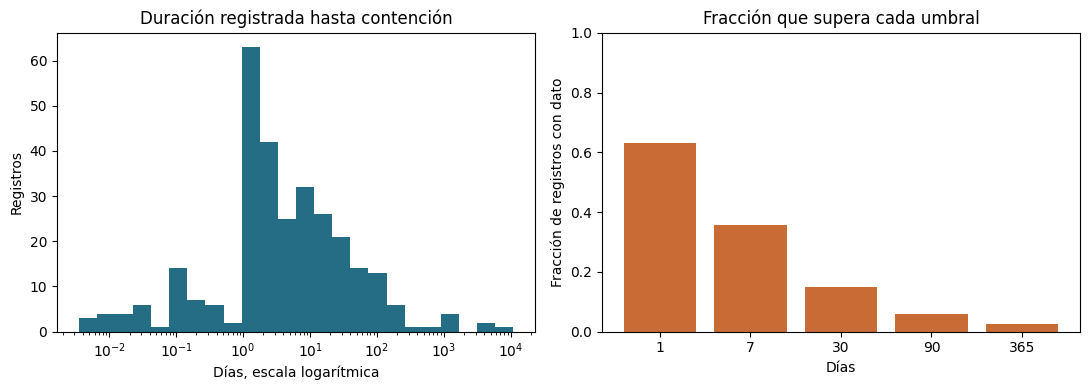

In [4]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(subset.days,bins=np.logspace(np.log10(subset.days.min()),np.log10(subset.days.max()),25),color='#256d85');axes[0].set_xscale('log');axes[0].set(title='Duración registrada hasta contención',xlabel='Días, escala logarítmica',ylabel='Registros')
thresholds=np.array([1,7,30,90,365]); freq=np.array([(subset.days>x).mean() for x in thresholds]);axes[1].bar([str(x) for x in thresholds],freq,color='#c96b35');axes[1].set(title='Fracción que supera cada umbral',xlabel='Días',ylabel='Fracción de registros con dato',ylim=(0,1));plt.tight_layout();plt.show()

## 4. Tiempo por año y sensibilidad a meses
Los años con pocos registros no permiten comparaciones estables. Para evitar una interpretación artificialmente precisa, las tres variantes mantienen el mismo conjunto y cambian únicamente la equivalencia de un mes en días. El año del incidente no es necesariamente año de contención.

In [5]:
ann=subset.groupby(year).days.agg(registros='size',mediana_dias='median')
ann=ann[ann.registros>=10].copy()
print('Años con al menos 10 duraciones disponibles:',len(ann))
ann.tail(12).round(2)

Años con al menos 10 duraciones disponibles: 9


,registros,mediana_dias
timeline.incident.year,,
2013,39,1.0
2014,27,1.0
2015,38,10.5
2016,37,2.0
2017,25,2.0
2018,18,5.0
2019,44,4.5
2020,19,14.0
2021,12,8.5


In [6]:
variants=[]
for month_days in [28,30,31]:
    adjusted=subset.days.copy()
    m=subset.unit.eq('Months');adjusted.loc[m]=subset.loc[m,value]*month_days
    variants.append({'dias_por_mes':month_days,'mediana':adjusted.median(),'p90':adjusted.quantile(.9),'proporcion_mayor_30_dias':(adjusted>30).mean()})
pd.DataFrame(variants).round(4)

,dias_por_mes,mediana,p90,proporcion_mayor_30_dias
0,28,3.0,56.0,0.1510
1,30,3.0,60.0,0.1510
2,31,3.0,62.0,0.1913


## 5. Comparación exploratoria de modelos de duración
Se comparan una lognormal y una Weibull con soporte positivo (ubicación fija en cero). Las distribuciones se ajustan solo al 70 % de las duraciones, asignado aleatoriamente con semilla 42, y se reporta en el 30 % restante la máxima distancia entre CDF empírica y predicha. Es un diagnóstico descriptivo en observaciones divulgadas y discretizadas; no se reportan p-valores KS porque existen empates, selección y posible dependencia de incidentes. La partición aleatoria no representa validación temporal. No hay información de censura.

In [7]:
from scipy import stats
from sklearn.model_selection import train_test_split
train,holdout=train_test_split(subset.days.to_numpy(),test_size=.30,random_state=42)
models={'Lognormal':stats.lognorm,'Weibull':stats.weibull_min}; rows=[]
for name,dist in models.items():
    pars=dist.fit(train,floc=0)
    grid=np.sort(holdout);cdf=dist.cdf(grid,*pars);n_eval=len(grid)
    ks=max(np.max(np.arange(1,n_eval+1)/n_eval-cdf),np.max(cdf-np.arange(0,n_eval)/n_eval))
    rows.append({'modelo':name,'n_ajuste':len(train),'n_prueba':n_eval,'KS_descriptivo':ks,'mediana_modelo_dias':dist.ppf(.5,*pars),'p90_modelo_dias':dist.ppf(.9,*pars)})
models_comparison=pd.DataFrame(rows); models_comparison.round(3)

,modelo,n_ajuste,n_prueba,KS_descriptivo,mediana_modelo_dias,p90_modelo_dias
0,Lognormal,208,90,0.167,3.417,84.137
1,Weibull,208,90,0.177,4.575,106.806


## 6. Conclusiones y siguiente decisión
Las tablas y figuras describen únicamente los registros con duración positiva y unidad interpretable. La baja cobertura y la selección de incidentes divulgados impiden extrapolar a toda la población o estimar SLA de recuperación; tampoco observamos exposiciones, controles, censura ni cambios de capacidad. Para diseñar objetivos institucionales se necesitan inicio, contención, restablecimiento, cierre y estado de censura por incidente, más sistemas afectados y criterios de completitud.

**Siguiente paso:** reconciliar cronologías y definir por anticipado el evento de interés, el horizonte y las exclusiones antes de estimar supervivencia con censura.